In [1]:
!pip install pandas requests matplotlib seaborn scipy

In [2]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from io import StringIO
from datetime import datetime, timezone
from pathlib import Path

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
# Localização da raiz do projeto
ROOT_DIR = Path.cwd().parent

# Diretórios de dados
RAW_DIR = ROOT_DIR / "data" / "raw"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
IMAGES_DIR = ROOT_DIR / "images"

# Criar diretórios caso ainda não existam
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print("Raiz do projeto:", ROOT_DIR)
print("Diretórios configurados com sucesso!")

Raiz do projeto: c:\Users\Micro\Desktop\Art\General Codes\GeneralCodes\explanets-data-analysis
Diretórios configurados com sucesso!


In [4]:
# Endpoint da API do NASA Exoplanet Archive
API_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

# Consulta SQL para selecionar as variáveis do projeto
QUERY = """
SELECT
    pl_name,
    hostname,
    pl_rade,
    pl_orbper,
    discoverymethod,
    disc_year,
    sy_dist
FROM pscomppars
"""

print("Consulta SQL preparada.")

Consulta SQL preparada.


In [6]:
# Enviar a consulta para a API da NASA
response = requests.get(
    API_URL,
    params={
        "query": QUERY,
        "format": "csv"
    },
    timeout=120
)

# Interromper se a requisição falhar
response.raise_for_status()

# Converter a resposta CSV em um DataFrame
df_raw = pd.read_csv(StringIO(response.text))

# Registrar o momento da coleta em UTC
collection_date = datetime.now(timezone.utc).isoformat()

# Exibir um resumo da coleta
print("Coleta concluída!")
print("Data da coleta (UTC):", collection_date)
print("Quantidade de linhas:", len(df_raw))
print("Quantidade de colunas:", len(df_raw.columns))

Coleta concluída!
Data da coleta (UTC): 2026-10-21T17:08:48.540086+00:00
Quantidade de linhas: 6451
Quantidade de colunas: 7


In [7]:
display(df_raw.head(10))

,pl_name,hostname,pl_rade,pl_orbper,discoverymethod,disc_year,sy_dist
0,55 Cnc b,55 Cnc,13.900,14.651552,Radial Velocity,1996,12.58550
1,55 Cnc c,55 Cnc,8.510,44.393600,Radial Velocity,2004,12.58550
2,55 Cnc d,55 Cnc,13.000,4799.000000,Radial Velocity,2002,12.58550
3,55 Cnc e,55 Cnc,1.875,0.736547,Radial Velocity,2004,12.58550
4,55 Cnc f,55 Cnc,7.590,260.580000,Radial Velocity,2007,12.58550
5,GJ 1214 b,GJ 1214,2.733,1.580405,Transit,2009,14.64270
6,GJ 436 b,GJ 436,4.170,2.643883,Radial Velocity,2004,9.75321
7,HAT-P-12 b,HAT-P-12,10.749,3.213060,Transit,2009,142.75100
8,HAT-P-13 b,HAT-P-13,14.258,2.916250,Transit,2009,246.81000
9,HAT-P-13 c,HAT-P-13,12.300,446.270000,Radial Velocity,2009,246.81000


In [8]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6451 non-null   object 
 1   hostname         6451 non-null   object 
 2   pl_rade          6401 non-null   float64
 3   pl_orbper        6097 non-null   float64
 4   discoverymethod  6451 non-null   object 
 5   disc_year        6451 non-null   int64  
 6   sy_dist          6423 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 352.9+ KB


In [9]:
raw_file = RAW_DIR / "exoplanets_raw.csv"

df_raw.to_csv(raw_file, index=False)

print(f"Dados originais salvos em: {raw_file}")

Dados originais salvos em: c:\Users\Micro\Desktop\Art\General Codes\GeneralCodes\explanets-data-analysis\data\raw\exoplanets_raw.csv


### EDA

In [10]:
# Dimensões do conjunto de dados
print(f"Linhas: {df_raw.shape[0]}")
print(f"Colunas: {df_raw.shape[1]}")

# Tipos de dados e valores não nulos
df_raw.info()

Linhas: 6451
Colunas: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6451 non-null   object 
 1   hostname         6451 non-null   object 
 2   pl_rade          6401 non-null   float64
 3   pl_orbper        6097 non-null   float64
 4   discoverymethod  6451 non-null   object 
 5   disc_year        6451 non-null   int64  
 6   sy_dist          6423 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 352.9+ KB


In [11]:
# Quantidade de valores ausentes por coluna
missing_values = df_raw.isna().sum()

# Percentual de valores ausentes
missing_percentage = (
    df_raw.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "missing_values": missing_values,
    "missing_percentage": missing_percentage
}).sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_summary)

,missing_values,missing_percentage
pl_orbper,354,5.49
pl_rade,50,0.78
sy_dist,28,0.43
pl_name,0,0.00
hostname,0,0.00
discoverymethod,0,0.00
disc_year,0,0.00


In [12]:
# Linhas inteiramente duplicadas
duplicate_count = df_raw.duplicated().sum()

print(f"Linhas completamente duplicadas: {duplicate_count}")

# Quantidade de nomes de planetas repetidos
repeated_planets = df_raw["pl_name"].duplicated().sum()

print(f"Nomes de planetas repetidos: {repeated_planets}")

Linhas completamente duplicadas: 0
Nomes de planetas repetidos: 0


In [13]:
method_counts = df_raw["discoverymethod"].value_counts(
    dropna=False
)

display(method_counts.to_frame(name="number_of_planets"))

,number_of_planets
discoverymethod,
Transit,4785
Radial Velocity,1204
Microlensing,292
Imaging,98
Transit Timing Variations,29
Eclipse Timing Variations,17
Orbital Brightness Modulation,9
Pulsar Timing,8
Astrometry,6


In [14]:
display(
    df_raw[
        ["pl_rade", "pl_orbper", "disc_year", "sy_dist"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
pl_rade,6401.0,5.844661,5.400441e+00,0.309800,1.850000,2.8600,11.900000,8.720587e+01
pl_orbper,6097.0,70215.799122,5.150759e+06,0.090706,4.288178,10.6413,37.993273,4.020000e+08
disc_year,6451.0,2017.403038,5.202505e+00,1992.000000,2014.000000,2016.0000,2021.000000,2.026000e+03
sy_dist,6423.0,704.833229,1.230179e+03,1.301190,99.643550,349.0000,817.261000,8.500000e+03


### Preparação dos Dados

In [15]:
df = df_raw.copy()

numeric_columns = [
    "pl_rade",
    "pl_orbper",
    "disc_year",
    "sy_dist"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Cópia de trabalho criada.")
print(df.dtypes)

Cópia de trabalho criada.
pl_name             object
hostname            object
pl_rade            float64
pl_orbper          float64
discoverymethod     object
disc_year            int64
sy_dist            float64
dtype: object


In [16]:
invalid_summary = pd.DataFrame({
    "zero_or_negative": [
        (df["pl_rade"].dropna() <= 0).sum(),
        (df["pl_orbper"].dropna() <= 0).sum()
    ],
    "missing": [
        df["pl_rade"].isna().sum(),
        df["pl_orbper"].isna().sum()
    ]
}, index=["pl_rade", "pl_orbper"])

display(invalid_summary)

,zero_or_negative,missing
pl_rade,0,50
pl_orbper,0,354


In [17]:
df_analysis = df.dropna(
    subset=[
        "pl_rade",
        "pl_orbper",
        "discoverymethod"
    ]
).copy()

# Excluir valores fisicamente inválidos para esta análise
df_analysis = df_analysis[
    (df_analysis["pl_rade"] > 0) &
    (df_analysis["pl_orbper"] > 0)
].copy()

print("Registros originais:", len(df_raw))
print("Registros na análise:", len(df_analysis))

retention = len(df_analysis) / len(df_raw) * 100
print(f"Retenção da amostra: {retention:.2f}%")

Registros originais: 6451
Registros na análise: 6050
Retenção da amostra: 93.78%


In [18]:
display(
    df_analysis[
        ["pl_name", "pl_rade", "pl_orbper", "discoverymethod"]
    ].head(10)
)

print("\nValores ausentes nas variáveis principais:")
display(
    df_analysis[
        ["pl_rade", "pl_orbper", "discoverymethod"]
    ].isna().sum()
)

,pl_name,pl_rade,pl_orbper,discoverymethod
0,55 Cnc b,13.900,14.651552,Radial Velocity
1,55 Cnc c,8.510,44.393600,Radial Velocity
2,55 Cnc d,13.000,4799.000000,Radial Velocity
3,55 Cnc e,1.875,0.736547,Radial Velocity
4,55 Cnc f,7.590,260.580000,Radial Velocity
5,GJ 1214 b,2.733,1.580405,Transit
6,GJ 436 b,4.170,2.643883,Radial Velocity
7,HAT-P-12 b,10.749,3.213060,Transit
8,HAT-P-13 b,14.258,2.916250,Transit
9,HAT-P-13 c,12.300,446.270000,Radial Velocity



Valores ausentes nas variáveis principais:


pl_rade            0
pl_orbper          0
discoverymethod    0
dtype: int64

In [19]:
processed_file = PROCESSED_DIR / "exoplanets_analysis.csv"

df_analysis.to_csv(processed_file, index=False)

print(f"Amostra salva em: {processed_file}")

Amostra salva em: c:\Users\Micro\Desktop\Art\General Codes\GeneralCodes\explanets-data-analysis\data\processed\exoplanets_analysis.csv


In [ ]:
method_counts = (
    df_analysis["discoverymethod"]
    .value_counts()
    .rename_axis("discovery_method")
    .reset_index(name="planet_count")
)

method_counts["percentage"] = (
    method_counts["planet_count"]
    / len(df_analysis)
    * 100
).round(2)

display(method_counts)

,discovery_method,planet_count,percentage
0,Transit,4784,79.07
1,Radial Velocity,1167,19.29
2,Transit Timing Variations,28,0.46
3,Imaging,25,0.41
4,Eclipse Timing Variations,15,0.25
5,Microlensing,12,0.20
6,Orbital Brightness Modulation,6,0.10
7,Astrometry,6,0.10
8,Pulsar Timing,5,0.08
9,Pulsation Timing Variations,2,0.03


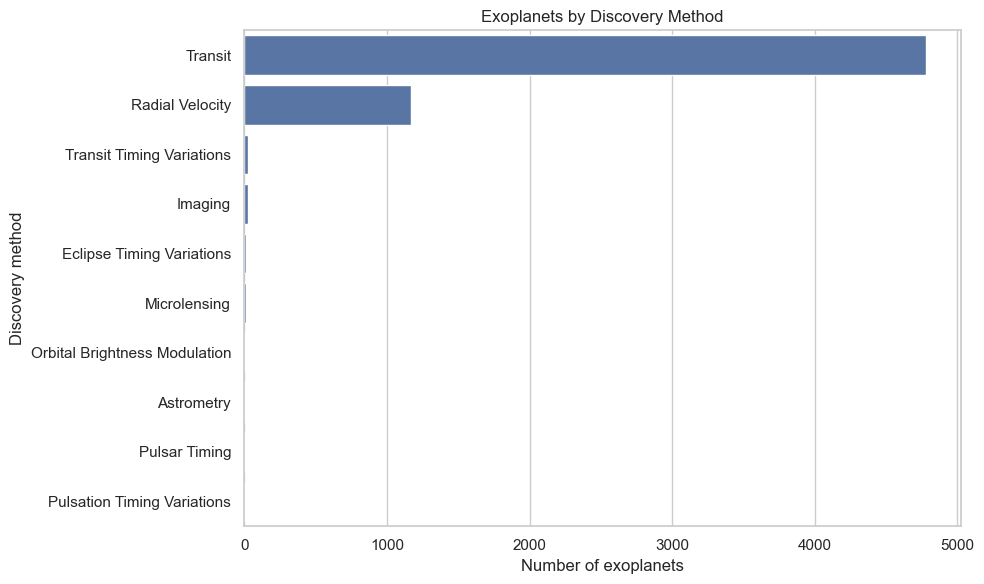

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=method_counts,
    x="planet_count",
    y="discovery_method"
)

plt.title("Exoplanets by Discovery Method")
plt.xlabel("Number of exoplanets")
plt.ylabel("Discovery method")
plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "discovery_methods.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

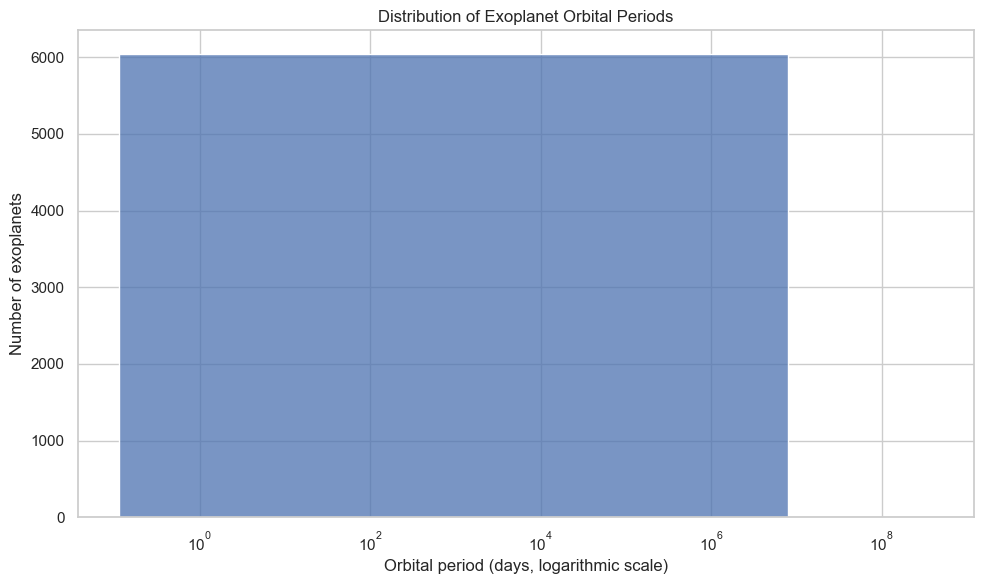

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_analysis,
    x="pl_orbper",
    bins=50
)

plt.xscale("log")

plt.title("Distribution of Exoplanet Orbital Periods")
plt.xlabel("Orbital period (days, logarithmic scale)")
plt.ylabel("Number of exoplanets")
plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "orbital_period_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

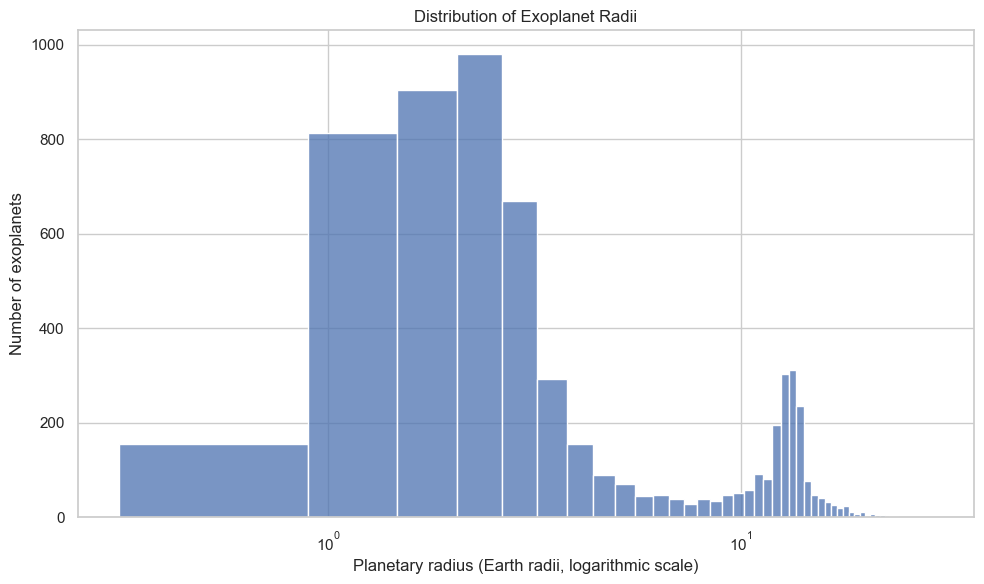

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_analysis,
    x="pl_rade",
    bins=50
)

plt.xscale("log")

plt.title("Distribution of Exoplanet Radii")
plt.xlabel("Planetary radius (Earth radii, logarithmic scale)")
plt.ylabel("Number of exoplanets")
plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "planetary_radius_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

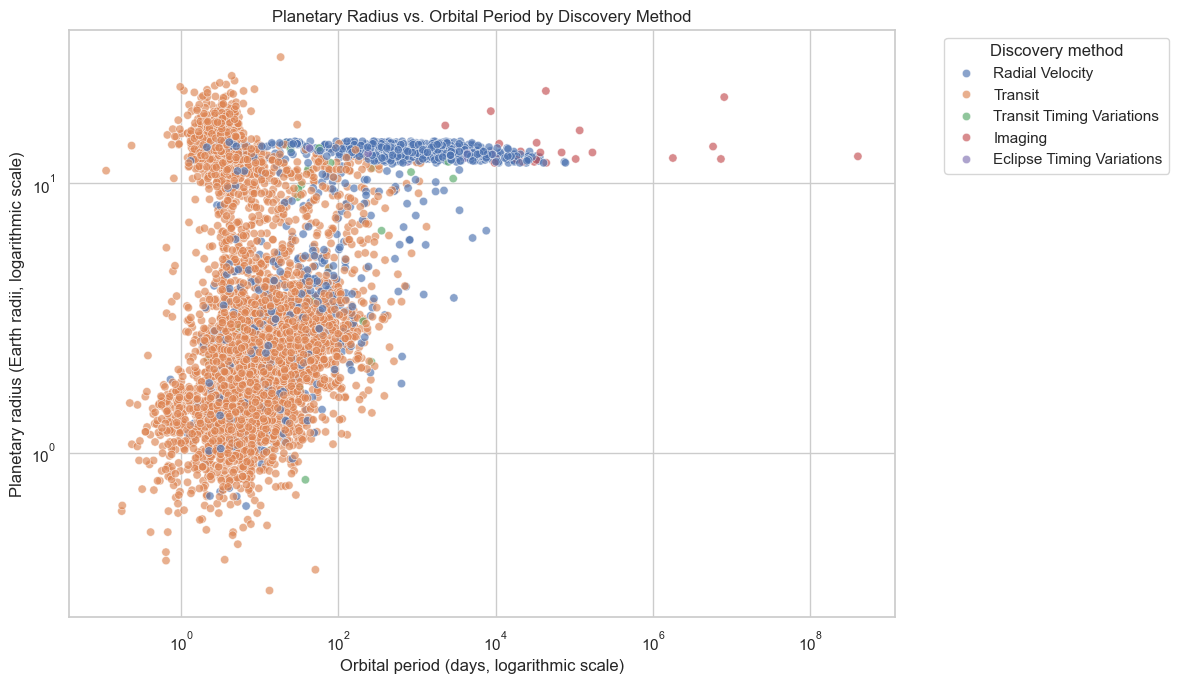

In [ ]:
top_methods = (
    df_analysis["discoverymethod"]
    .value_counts()
    .head(5)
    .index
)

plot_df = df_analysis[
    df_analysis["discoverymethod"].isin(top_methods)
].copy()

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_df,
    x="pl_orbper",
    y="pl_rade",
    hue="discoverymethod",
    alpha=0.65
)

plt.xscale("log")
plt.yscale("log")

plt.title("Planetary Radius vs. Orbital Period by Discovery Method")
plt.xlabel("Orbital period (days, logarithmic scale)")
plt.ylabel("Planetary radius (Earth radii, logarithmic scale)")
plt.legend(
    title="Discovery method",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "radius_vs_orbital_period.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
import numpy as np

dados = df_analysis[["pl_rade", "pl_orbper"]].copy()

dados["log_raio"] = np.log10(dados["pl_rade"])
dados["log_periodo"] = np.log10(dados["pl_orbper"])

correlacao = dados["log_raio"].corr(dados["log_periodo"])

print(f"Correlação de Pearson: {correlacao:.3f}")

Correlação de Pearson: 0.420


In [26]:
import numpy as np
import pandas as pd

# Criar uma cópia com as colunas necessárias
dados = df_analysis[
    ["pl_rade", "pl_orbper", "discoverymethod"]
].copy()

# Transformar raio e período em escala logarítmica
dados["log_raio"] = np.log10(dados["pl_rade"])
dados["log_periodo"] = np.log10(dados["pl_orbper"])

# Calcular a correlação para cada método de descoberta
correlacoes = dados.groupby("discoverymethod").apply(
    lambda grupo: grupo["log_raio"].corr(grupo["log_periodo"])
)

# Ordenar do maior para o menor
correlacoes = correlacoes.sort_values(ascending=False)

print(correlacoes.round(3))

discoverymethod
Pulsation Timing Variations      1.000
Orbital Brightness Modulation    0.959
Radial Velocity                  0.659
Transit Timing Variations        0.429
Imaging                          0.033
Transit                          0.015
Astrometry                      -0.320
Eclipse Timing Variations       -0.361
Microlensing                    -0.507
Pulsar Timing                   -0.569
dtype: float64
